# 🪟 SAM-Based Building Segmentation

**Workflow:**
1. You manually select 1-4 example windows (bounding boxes)
2. SAM segments those windows precisely
3. We use the window features to find ALL similar windows automatically
4. Everything else = building (walls/roof)

This approach is much more accurate than pure color-based detection!

## 1. Setup & Install SAM

In [1]:
# Install SAM
!pip install -q git+https://github.com/facebookresearch/segment-anything.git
!pip install -q opencv-python-headless

# Download SAM weights (ViT-B is smaller and faster)
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

print("✅ SAM installed and weights downloaded!")

  Preparing metadata (setup.py) ... done
✅ SAM installed and weights downloaded!


In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from segment_anything import sam_model_registry, SamPredictor, SamAutomaticMaskGenerator
import torch

# Check GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")
if device == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cpu


## 2. Load SAM Model

In [3]:
# Load SAM
SAM_CHECKPOINT = "sam_vit_b_01ec64.pth"
MODEL_TYPE = "vit_b"

print("Loading SAM model...")
sam = sam_model_registry[MODEL_TYPE](checkpoint=SAM_CHECKPOINT)
sam.to(device=device)

predictor = SamPredictor(sam)
print("✅ SAM ready!")

Loading SAM model...
✅ SAM ready!


## 3. Upload Your Thermal Image

📤 Upload your thermal image:


Saving IRX_2927.JPG to IRX_2927.JPG

📐 Image size: 640 x 512


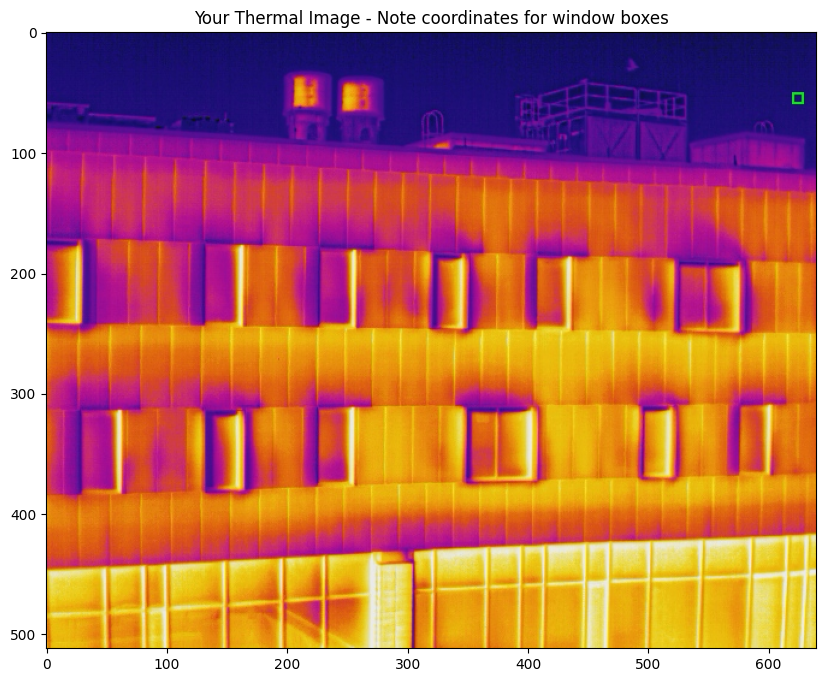

In [4]:
print("📤 Upload your thermal image:")
uploaded = files.upload()
IMAGE_PATH = list(uploaded.keys())[0]

# Load image
image_bgr = cv2.imread(IMAGE_PATH)
rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
h, w = gray.shape

print(f"\n📐 Image size: {w} x {h}")

plt.figure(figsize=(12, 8))
plt.imshow(rgb)
plt.title('Your Thermal Image - Note coordinates for window boxes')
plt.axis('on')  # Keep axis ON to see coordinates
plt.show()

## 4. 👆 Define Your Window Boxes

**Instructions:**
1. Look at the image above with coordinates
2. Identify 2-6 example windows
3. Note their approximate bounding boxes: `[x_left, y_top, x_right, y_bottom]`
4. Edit the `WINDOW_BOXES` list below

**Tip:** Pick windows from different rows/areas for best results!

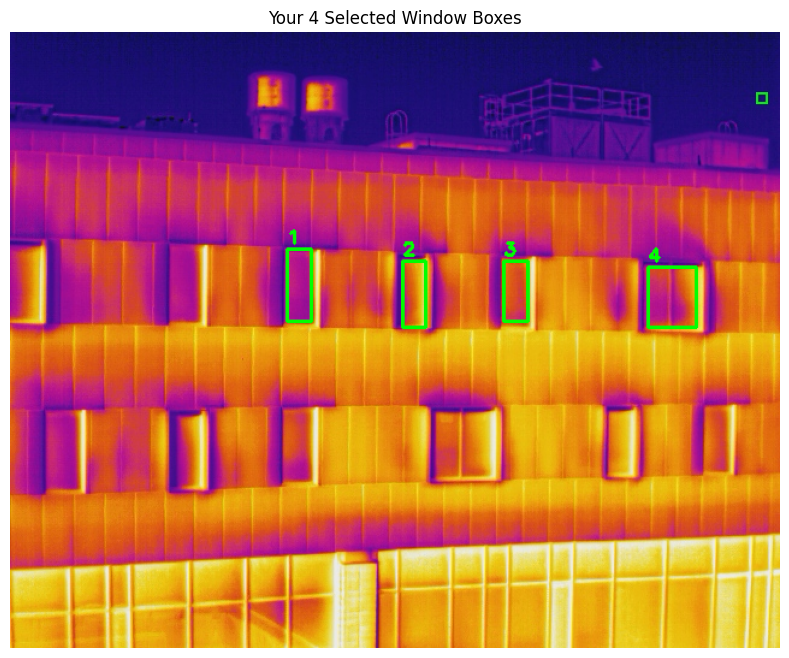

✅ 4 window boxes defined
If these look wrong, edit WINDOW_BOXES above and re-run this cell.


In [5]:
# ============================================
# 👇 EDIT THESE BOXES FOR YOUR IMAGE 👇
# Format: [x_left, y_top, x_right, y_bottom]
# ============================================

WINDOW_BOXES = [
    [230, 180, 250, 240],   # Window 1
    [326, 190, 345, 245],   # Window 2
    [410, 190, 430, 240],   # Window 3
    [530, 195, 570, 245],   # Window 4
]

# ============================================

# Preview your boxes
vis = rgb.copy()
for i, (x0, y0, x1, y1) in enumerate(WINDOW_BOXES):
    cv2.rectangle(vis, (x0, y0), (x1, y1), (0, 255, 0), 2)
    cv2.putText(vis, str(i+1), (x0, y0-5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(vis)
plt.title(f"Your {len(WINDOW_BOXES)} Selected Window Boxes")
plt.axis('off')
plt.show()

print(f"✅ {len(WINDOW_BOXES)} window boxes defined")
print("If these look wrong, edit WINDOW_BOXES above and re-run this cell.")

## 5. Segment Selected Windows with SAM

In [6]:
# Set image for SAM
predictor.set_image(rgb)

def segment_with_box(predictor, box):
    """
    Use SAM to segment a region given a bounding box.
    Returns the best mask.
    """
    box_array = np.array(box)

    masks, scores, logits = predictor.predict(
        point_coords=None,
        point_labels=None,
        box=box_array[None, :],  # SAM expects [1, 4] shape
        multimask_output=True
    )

    # Return highest scoring mask
    best_idx = np.argmax(scores)
    return masks[best_idx], scores[best_idx]

# Segment each selected window
seed_masks = []
seed_scores = []

print("Segmenting selected windows with SAM...")
for i, box in enumerate(WINDOW_BOXES):
    mask, score = segment_with_box(predictor, box)
    seed_masks.append(mask)
    seed_scores.append(score)
    print(f"  Window {i+1}: score = {score:.3f}")

print(f"\n✅ Segmented {len(seed_masks)} seed windows")

Segmenting selected windows with SAM...
  Window 1: score = 0.981
  Window 2: score = 0.975
  Window 3: score = 0.977
  Window 4: score = 0.975

✅ Segmented 4 seed windows


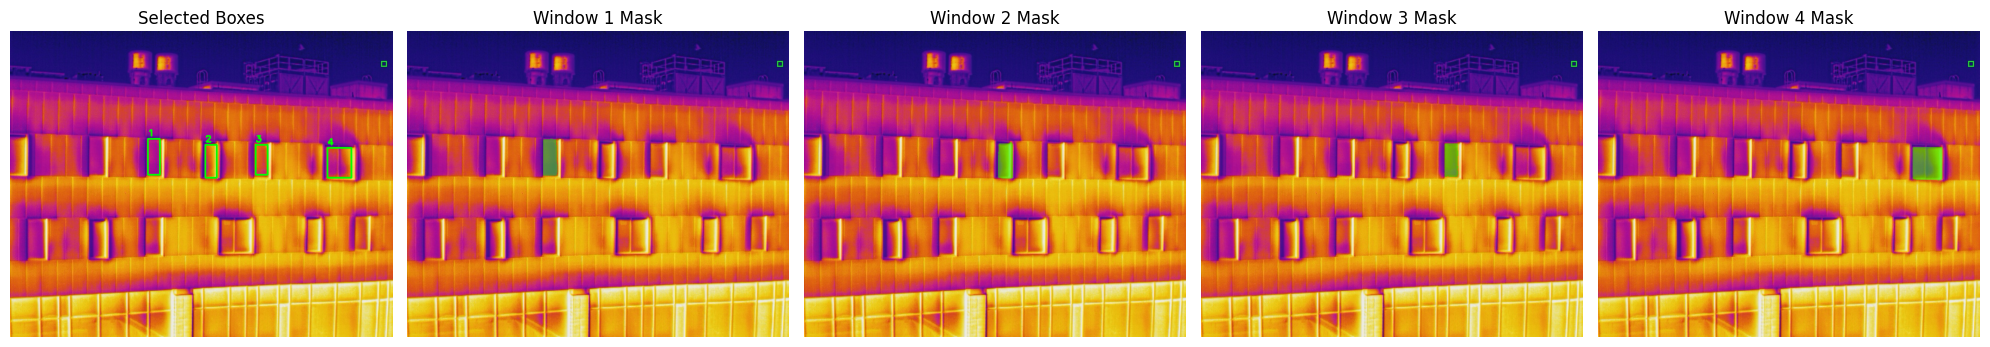

In [7]:
# Visualize seed window masks
fig, axes = plt.subplots(1, len(seed_masks) + 1, figsize=(4 * (len(seed_masks) + 1), 4))

# Original with boxes
axes[0].imshow(vis)
axes[0].set_title('Selected Boxes')
axes[0].axis('off')

# Individual masks
for i, mask in enumerate(seed_masks):
    overlay = rgb.copy()
    overlay[mask] = overlay[mask] * 0.5 + np.array([0, 255, 0]) * 0.5
    axes[i+1].imshow(overlay.astype(np.uint8))
    axes[i+1].set_title(f'Window {i+1} Mask')
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()

## 6. Extract Window Features
Learn what a "window" looks like from your examples.

In [8]:
def extract_region_features(image_rgb, image_gray, mask):
    """
    Extract features from a segmented region.
    """
    if np.sum(mask) == 0:
        return None

    # Get bounding box
    coords = np.where(mask)
    y_min, y_max = coords[0].min(), coords[0].max()
    x_min, x_max = coords[1].min(), coords[1].max()

    height = y_max - y_min
    width = x_max - x_min

    # Color features (from RGB)
    pixels_rgb = image_rgb[mask]
    mean_color = np.mean(pixels_rgb, axis=0)
    std_color = np.std(pixels_rgb, axis=0)

    # Intensity features (from grayscale)
    pixels_gray = image_gray[mask]
    mean_intensity = np.mean(pixels_gray)
    std_intensity = np.std(pixels_gray)

    # Shape features
    area = np.sum(mask)
    bbox_area = height * width
    extent = area / bbox_area if bbox_area > 0 else 0
    aspect_ratio = width / height if height > 0 else 1

    return {
        'mean_color': mean_color,
        'std_color': std_color,
        'mean_intensity': mean_intensity,
        'std_intensity': std_intensity,
        'area': area,
        'width': width,
        'height': height,
        'aspect_ratio': aspect_ratio,
        'extent': extent
    }

# Extract features from seed windows
seed_features = []
for mask in seed_masks:
    feat = extract_region_features(rgb, gray, mask)
    if feat:
        seed_features.append(feat)

# Calculate average window features
avg_features = {
    'mean_color': np.mean([f['mean_color'] for f in seed_features], axis=0),
    'mean_intensity': np.mean([f['mean_intensity'] for f in seed_features]),
    'std_intensity': np.mean([f['std_intensity'] for f in seed_features]),
    'area': np.mean([f['area'] for f in seed_features]),
    'area_std': np.std([f['area'] for f in seed_features]),
    'aspect_ratio': np.mean([f['aspect_ratio'] for f in seed_features]),
    'extent': np.mean([f['extent'] for f in seed_features])
}

print("📊 Learned Window Features:")
print(f"  Mean RGB: {avg_features['mean_color'].astype(int)}")
print(f"  Mean Intensity: {avg_features['mean_intensity']:.1f}")
print(f"  Avg Area: {avg_features['area']:.0f} ± {avg_features['area_std']:.0f} pixels")
print(f"  Aspect Ratio: {avg_features['aspect_ratio']:.2f}")
print(f"  Extent (rectangularity): {avg_features['extent']:.2f}")

📊 Learned Window Features:
  Mean RGB: [203  78  75]
  Mean Intensity: 115.7
  Avg Area: 1714 ± 599 pixels
  Aspect Ratio: 0.52
  Extent (rectangularity): 1.02


## 7. Generate ALL Masks with SAM
Let SAM find every distinct region, then we filter for windows.

In [9]:
# Use SAM's automatic mask generator
mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,
    pred_iou_thresh=0.86,
    stability_score_thresh=0.92,
    min_mask_region_area=100,
)

print("Generating all masks (this may take a minute)...")
all_masks = mask_generator.generate(rgb)
print(f"✅ Generated {len(all_masks)} masks")

Generating all masks (this may take a minute)...
✅ Generated 100 masks


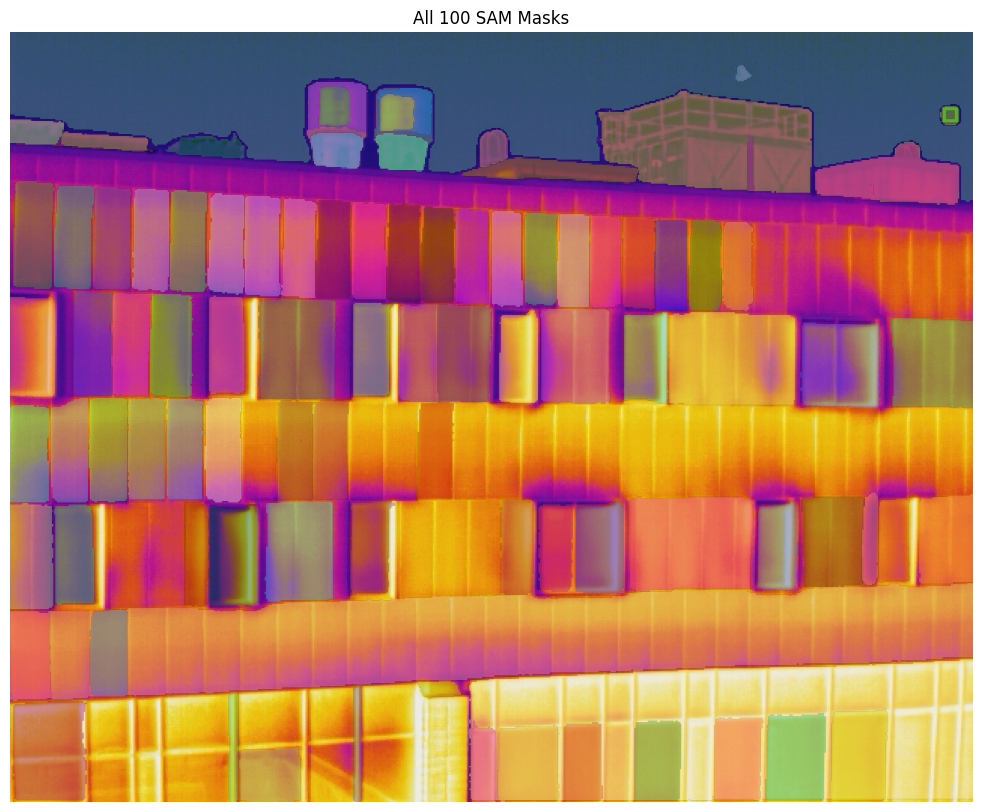

In [10]:
# Visualize all SAM masks
def show_all_masks(image, masks):
    plt.figure(figsize=(14, 10))
    plt.imshow(image)

    sorted_masks = sorted(masks, key=lambda x: x['area'], reverse=True)

    for mask_data in sorted_masks:
        m = mask_data['segmentation']
        color = np.random.random(3)
        colored_mask = np.zeros((*m.shape, 4))
        colored_mask[m] = [*color, 0.4]
        plt.imshow(colored_mask)

    plt.title(f'All {len(masks)} SAM Masks')
    plt.axis('off')
    plt.show()

show_all_masks(rgb, all_masks)

## 8. Find All Windows (Similar to Seeds)

In [11]:
def is_similar_to_window(mask_data, avg_features, image_rgb, image_gray, tolerance=2.0):
    """
    Check if a mask is similar to our seed windows.
    """
    mask = mask_data['segmentation']
    feat = extract_region_features(image_rgb, image_gray, mask)

    if feat is None:
        return False, 0

    # Size check - within tolerance of average window size
    area_min = avg_features['area'] / (tolerance * 2)
    area_max = avg_features['area'] * (tolerance * 2)
    if not (area_min < feat['area'] < area_max):
        return False, 0

    # Aspect ratio check
    aspect_diff = abs(feat['aspect_ratio'] - avg_features['aspect_ratio'])
    if aspect_diff > 1.0:  # Allow some variation
        return False, 0

    # Color similarity (Euclidean distance in RGB space)
    color_dist = np.linalg.norm(feat['mean_color'] - avg_features['mean_color'])
    max_color_dist = 80  # Threshold for color similarity

    # Intensity similarity
    intensity_diff = abs(feat['mean_intensity'] - avg_features['mean_intensity'])
    max_intensity_diff = 50

    # Calculate similarity score (lower is better)
    score = (
        color_dist / max_color_dist +
        intensity_diff / max_intensity_diff +
        aspect_diff
    )

    is_window = color_dist < max_color_dist and intensity_diff < max_intensity_diff

    return is_window, score

# Find all window-like masks
window_masks = []
window_scores = []

print("Finding all windows similar to your examples...")
for mask_data in all_masks:
    is_win, score = is_similar_to_window(mask_data, avg_features, rgb, gray)
    if is_win:
        window_masks.append(mask_data)
        window_scores.append(score)

print(f"✅ Found {len(window_masks)} windows!")

Finding all windows similar to your examples...
✅ Found 57 windows!


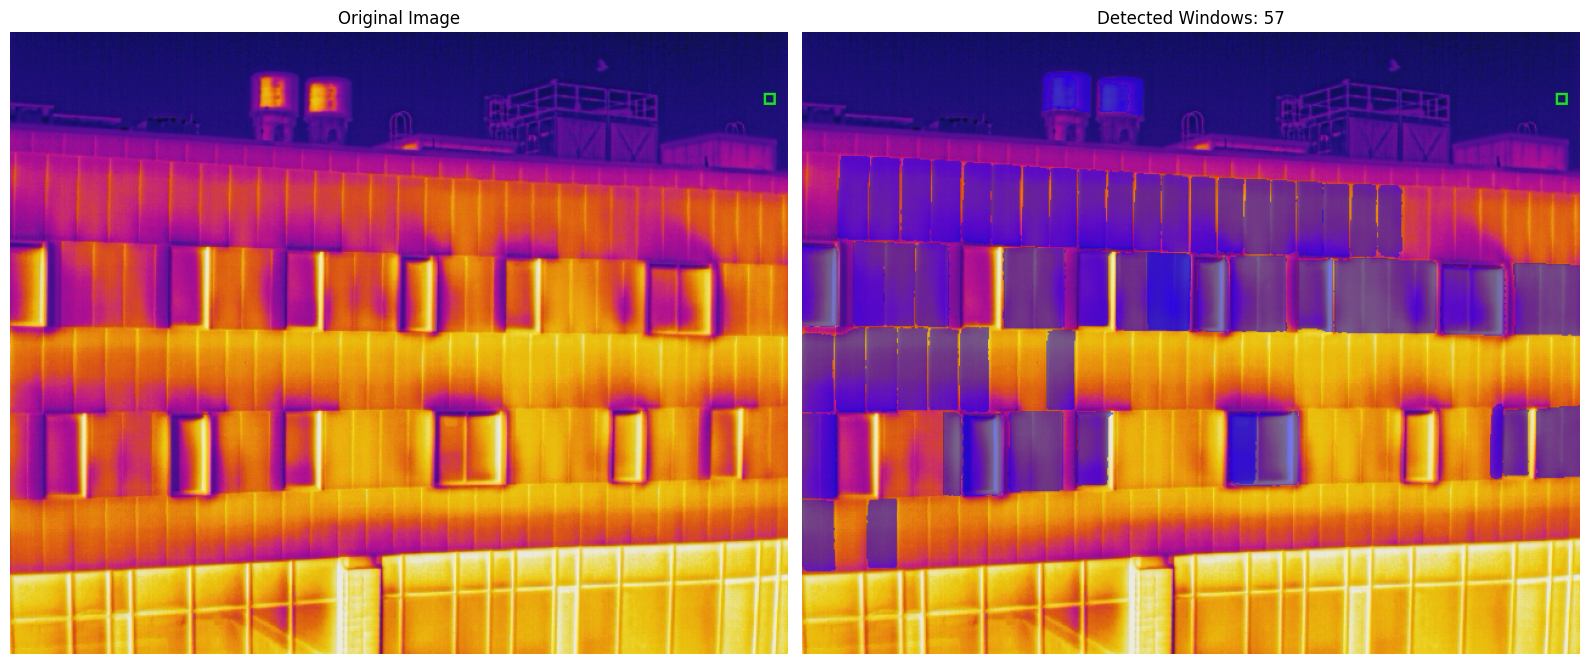

In [12]:
# Visualize detected windows
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Original
axes[0].imshow(rgb)
axes[0].set_title('Original Image')
axes[0].axis('off')

# Windows highlighted
overlay = rgb.copy().astype(float)
window_mask_combined = np.zeros((h, w), dtype=bool)

for mask_data in window_masks:
    m = mask_data['segmentation']
    window_mask_combined |= m
    overlay[m] = overlay[m] * 0.5 + np.array([0, 0, 255]) * 0.5

axes[1].imshow(overlay.astype(np.uint8))
axes[1].set_title(f'Detected Windows: {len(window_masks)}')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 9. Adjust Sensitivity (If Needed)

In [ ]:
#@title Adjust Window Detection Sensitivity { run: "auto" }
color_threshold = 80  #@param {type:"slider", min:20, max:150, step:10}
intensity_threshold = 50  #@param {type:"slider", min:20, max:100, step:5}
size_tolerance = 2.5  #@param {type:"slider", min:1.0, max:5.0, step:0.5}
aspect_tolerance = 1.2  #@param {type:"slider", min:0.5, max:2.0, step:0.1}

def find_windows_tuned(all_masks, avg_features, image_rgb, image_gray, params):
    window_masks = []

    for mask_data in all_masks:
        mask = mask_data['segmentation']
        feat = extract_region_features(image_rgb, image_gray, mask)

        if feat is None:
            continue

        # Size check
        area_min = avg_features['area'] / (params['size_tol'] * 2)
        area_max = avg_features['area'] * (params['size_tol'] * 2)
        if not (area_min < feat['area'] < area_max):
            continue

        # Aspect ratio check
        aspect_diff = abs(feat['aspect_ratio'] - avg_features['aspect_ratio'])
        if aspect_diff > params['aspect_tol']:
            continue

        # Color similarity
        color_dist = np.linalg.norm(feat['mean_color'] - avg_features['mean_color'])
        if color_dist > params['color_thresh']:
            continue

        # Intensity similarity
        intensity_diff = abs(feat['mean_intensity'] - avg_features['mean_intensity'])
        if intensity_diff > params['intensity_thresh']:
            continue

        window_masks.append(mask_data)

    return window_masks

params = {
    'color_thresh': color_threshold,
    'intensity_thresh': intensity_threshold,
    'size_tol': size_tolerance,
    'aspect_tol': aspect_tolerance
}

window_masks_tuned = find_windows_tuned(all_masks, avg_features, rgb, gray, params)

# Visualize
overlay = rgb.copy().astype(float)
for mask_data in window_masks_tuned:
    m = mask_data['segmentation']
    overlay[m] = overlay[m] * 0.5 + np.array([0, 0, 255]) * 0.5

plt.figure(figsize=(12, 8))
plt.imshow(overlay.astype(np.uint8))
plt.title(f'Windows Found: {len(window_masks_tuned)} (adjust sliders above)')
plt.axis('off')
plt.show()

# Update main list
window_masks = window_masks_tuned

## 10. Create Final Segmentation

In [ ]:
# Combine all window masks
window_mask_final = np.zeros((h, w), dtype=np.uint8)
for mask_data in window_masks:
    window_mask_final[mask_data['segmentation']] = 255

# Building = everything that's NOT a window
building_mask = 255 - window_mask_final

# Clean up building mask (remove small noise)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
building_mask = cv2.morphologyEx(building_mask, cv2.MORPH_OPEN, kernel)
building_mask = cv2.morphologyEx(building_mask, cv2.MORPH_CLOSE, kernel)

# Store final masks
component_masks = {
    'window': window_mask_final,
    'building': building_mask
}

print("📊 Final Segmentation:")
print(f"  Windows: {np.sum(window_mask_final > 0):,} pixels ({np.sum(window_mask_final > 0) / window_mask_final.size * 100:.1f}%)")
print(f"  Building: {np.sum(building_mask > 0):,} pixels ({np.sum(building_mask > 0) / building_mask.size * 100:.1f}%)")

In [ ]:
# Beautiful final visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# Original
axes[0, 0].imshow(rgb)
axes[0, 0].set_title('Original Thermal Image', fontsize=14)
axes[0, 0].axis('off')

# Window mask
axes[0, 1].imshow(window_mask_final, cmap='Blues')
axes[0, 1].set_title(f'Window Mask ({len(window_masks)} windows)', fontsize=14)
axes[0, 1].axis('off')

# Building mask
axes[1, 0].imshow(building_mask, cmap='Oranges')
axes[1, 0].set_title('Building Mask (Walls + Roof)', fontsize=14)
axes[1, 0].axis('off')

# Combined overlay
overlay = rgb.copy().astype(float) / 255
overlay[window_mask_final > 0] = overlay[window_mask_final > 0] * 0.5 + np.array([0, 0, 1]) * 0.5
overlay[building_mask > 0] = overlay[building_mask > 0] * 0.7 + np.array([1, 0.5, 0]) * 0.3

axes[1, 1].imshow(np.clip(overlay, 0, 1))
axes[1, 1].set_title('Final Segmentation', fontsize=14)
axes[1, 1].axis('off')

# Legend
from matplotlib.patches import Patch
legend = [
    Patch(facecolor='blue', alpha=0.5, label='Windows'),
    Patch(facecolor='orange', alpha=0.5, label='Building (Wall/Roof)')
]
axes[1, 1].legend(handles=legend, loc='upper right', fontsize=12)

plt.tight_layout()
plt.savefig('sam_segmentation_result.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n💾 Saved as 'sam_segmentation_result.png'")

## 11. Thermal Statistics

In [ ]:
print("\n" + "="*60)
print("🌡️  THERMAL STATISTICS")
print("="*60)

for name, mask in component_masks.items():
    if np.sum(mask > 0) > 0:
        values = gray[mask > 0]
        print(f"\n{name.upper()}:")
        print(f"  Mean Intensity: {np.mean(values):.1f}")
        print(f"  Std Deviation:  {np.std(values):.1f}")
        print(f"  Min / Max:      {np.min(values)} / {np.max(values)}")
        print(f"  Median:         {np.median(values):.1f}")

In [ ]:
# Histogram comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Windows
window_values = gray[window_mask_final > 0]
axes[0].hist(window_values, bins=50, color='blue', alpha=0.7, edgecolor='black')
axes[0].axvline(np.mean(window_values), color='red', linestyle='--', label=f'Mean: {np.mean(window_values):.1f}')
axes[0].set_title('Window Temperature Distribution')
axes[0].set_xlabel('Intensity')
axes[0].legend()

# Building
building_values = gray[building_mask > 0]
axes[1].hist(building_values, bins=50, color='orange', alpha=0.7, edgecolor='black')
axes[1].axvline(np.mean(building_values), color='red', linestyle='--', label=f'Mean: {np.mean(building_values):.1f}')
axes[1].set_title('Building Temperature Distribution')
axes[1].set_xlabel('Intensity')
axes[1].legend()

plt.tight_layout()
plt.show()

## 12. Export Results

In [ ]:
import os

output_dir = 'sam_segmentation_output'
os.makedirs(output_dir, exist_ok=True)

# Save masks
cv2.imwrite(f'{output_dir}/window_mask.png', window_mask_final)
cv2.imwrite(f'{output_dir}/building_mask.png', building_mask)

# Save labeled image (1=building, 2=window)
labels = np.ones((h, w), dtype=np.uint8)  # 1 = building
labels[window_mask_final > 0] = 2  # 2 = window
cv2.imwrite(f'{output_dir}/labels.png', labels)

# Save numpy data
np.savez(f'{output_dir}/segmentation_data.npz',
         image=rgb,
         gray=gray,
         window_mask=window_mask_final,
         building_mask=building_mask,
         labels=labels,
         window_boxes=np.array(WINDOW_BOXES))

# Save overlay
cv2.imwrite(f'{output_dir}/result_overlay.png',
            cv2.cvtColor((np.clip(overlay, 0, 1) * 255).astype(np.uint8), cv2.COLOR_RGB2BGR))

print(f"✅ Saved to '{output_dir}/'")
for f in sorted(os.listdir(output_dir)):
    print(f"  - {f}")

In [ ]:
# Download
!zip -r sam_segmentation.zip sam_segmentation_output/
files.download('sam_segmentation.zip')
print("📥 Download started!")

---
## Summary

**What this notebook does:**

1. ✅ You select 2-6 example windows manually
2. ✅ SAM segments those windows precisely
3. ✅ We learn what "windows" look like (color, size, shape)
4. ✅ SAM generates ALL possible masks in the image
5. ✅ We filter for masks that match window characteristics
6. ✅ Building = everything that's not a window

**For anomaly detection:**
- Compare window temperatures to find heat leaks
- Look for building areas with unusual temperatures
- The masks are ready in the exported `.npz` file!